# Random Forest / Classifier

**Type:** Guided machine-learning practice notebook (course-based study).  
**Purpose:** Explore the dataset and the modeling/preprocessing operations illustrated in the code below.  
**Data in this folder:** `14-income_evaluation.csv`.  
**Methods referenced:** `RandomForestClassifier`, `ColumnTransformer`.

> **Reproducibility note:** Run cells sequentially from this notebook’s folder. Outputs are historical study results, not independently validated benchmarks. The data files were supplied with the original archive; see `DATA_SOURCES.md` at the repository root for provenance checks.


In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("14-income_evaluation.csv")

In [3]:
df

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
32557,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
32558,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K
32559,22,Private,201490,HS-grad,9,Never-married,Adm-clerical,Own-child,White,Male,0,0,20,United-States,<=50K


In [4]:
df.columns

Index(['age', ' workclass', ' fnlwgt', ' education', ' education-num',
       ' marital-status', ' occupation', ' relationship', ' race', ' sex',
       ' capital-gain', ' capital-loss', ' hours-per-week', ' native-country',
       ' income'],
      dtype='object')

In [5]:
df.columns = [col.replace(" ", "").replace("-", "_") for col in df.columns]

In [6]:
df.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'education_num',
       'marital_status', 'occupation', 'relationship', 'race', 'sex',
       'capital_gain', 'capital_loss', 'hours_per_week', 'native_country',
       'income'],
      dtype='object')

In [7]:
df.isna().sum()

age               0
workclass         0
fnlwgt            0
education         0
education_num     0
marital_status    0
occupation        0
relationship      0
race              0
sex               0
capital_gain      0
capital_loss      0
hours_per_week    0
native_country    0
income            0
dtype: int64

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education_num   32561 non-null  int64 
 5   marital_status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital_gain    32561 non-null  int64 
 11  capital_loss    32561 non-null  int64 
 12  hours_per_week  32561 non-null  int64 
 13  native_country  32561 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


In [9]:
categorical_cols = [col for col in df.columns if df[col].dtype == "str"]
numerical_cols = [col for col in df.columns if df[col].dtype == "int64"]

In [10]:
print(categorical_cols)
print(numerical_cols)

[]
['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']


In [11]:
for col in categorical_cols:
    print(df[col].value_counts())

In [12]:
df["income"].value_counts() # imbalance

income
<=50K    24720
>50K      7841
Name: count, dtype: int64

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

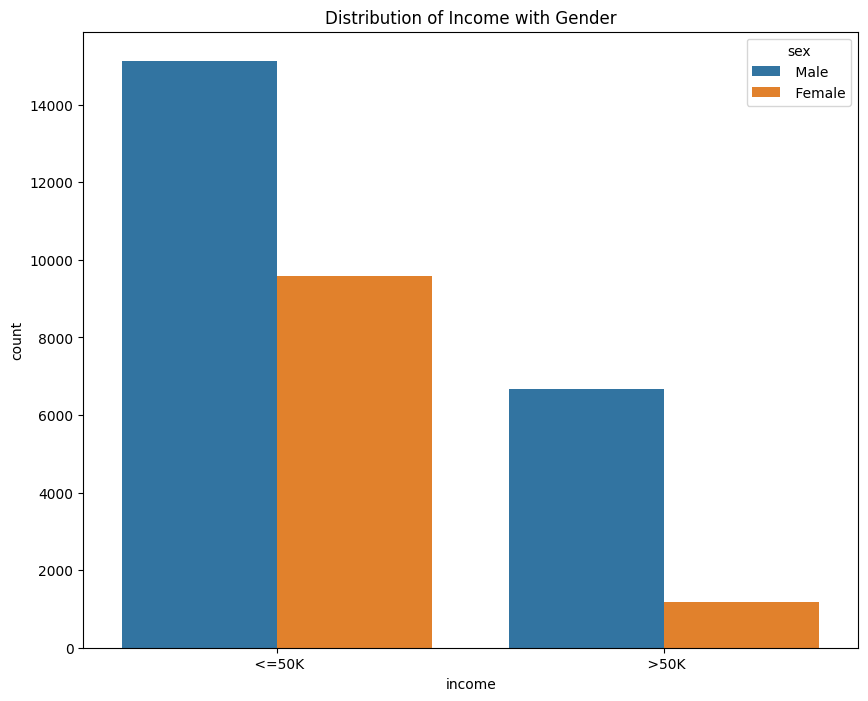

In [14]:
fig, ax = plt.subplots(figsize = (10, 8))
ax = sns.countplot(data = df, x = "income", hue = "sex")
plt.title("Distribution of Income with Gender")
plt.show()

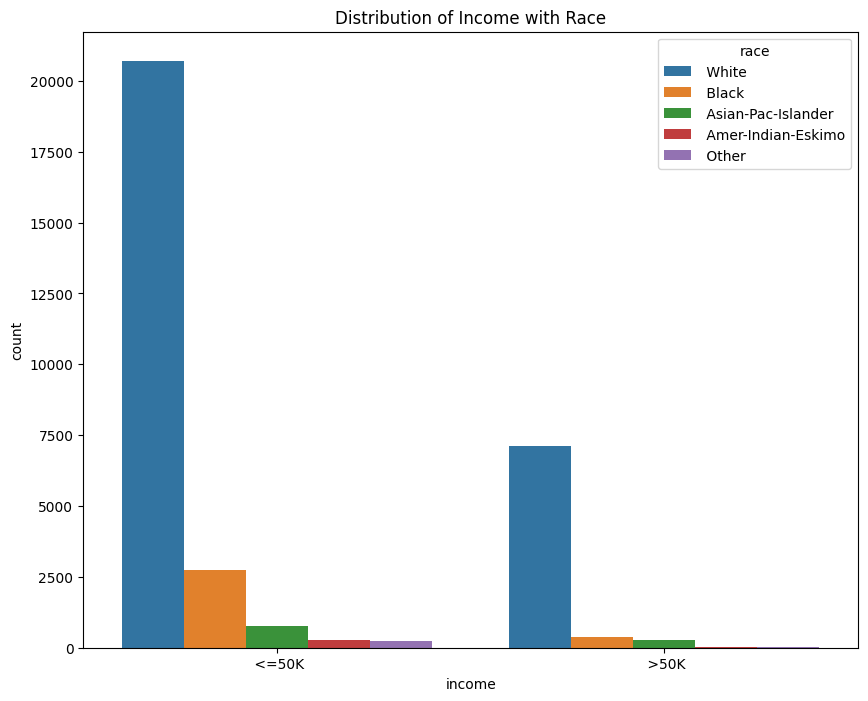

In [15]:
fig, ax = plt.subplots(figsize = (10, 8))
ax = sns.countplot(data = df, x = "income", hue = "race")
plt.title("Distribution of Income with Race")
plt.show()

In [16]:
df.describe()

,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


In [17]:
import numpy as np

In [18]:
for col in categorical_cols:
    print(df[col].value_counts())

In [19]:
df[["workclass", "occupation", "native_country"]] = df[["workclass", "occupation", "native_country"]].replace(" ?", np.nan)

In [20]:
df["workclass"].value_counts()

workclass
Private             22696
Self-emp-not-inc     2541
Local-gov            2093
State-gov            1298
Self-emp-inc         1116
Federal-gov           960
Without-pay            14
Never-worked            7
Name: count, dtype: int64

In [21]:
df["native_country"].value_counts()

native_country
United-States                 29170
Mexico                          643
Philippines                     198
Germany                         137
Canada                          121
Puerto-Rico                     114
El-Salvador                     106
India                           100
Cuba                             95
England                          90
Jamaica                          81
South                            80
China                            75
Italy                            73
Dominican-Republic               70
Vietnam                          67
Guatemala                        64
Japan                            62
Poland                           60
Columbia                         59
Taiwan                           51
Haiti                            44
Iran                             43
Portugal                         37
Nicaragua                        34
Peru                             31
France                           29
Greece       

In [22]:
df["occupation"].value_counts()

occupation
Prof-specialty       4140
Craft-repair         4099
Exec-managerial      4066
Adm-clerical         3770
Sales                3650
Other-service        3295
Machine-op-inspct    2002
Transport-moving     1597
Handlers-cleaners    1370
Farming-fishing       994
Tech-support          928
Protective-serv       649
Priv-house-serv       149
Armed-Forces            9
Name: count, dtype: int64

In [23]:
df[categorical_cols].isna().sum()

Series([], dtype: float64)

In [24]:
df[numerical_cols].isna().sum()

age               0
fnlwgt            0
education_num     0
capital_gain      0
capital_loss      0
hours_per_week    0
dtype: int64

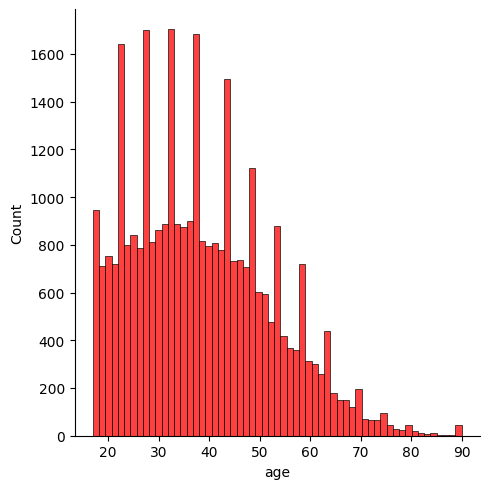

In [25]:
sns.displot(df["age"], color = "red")
plt.show()

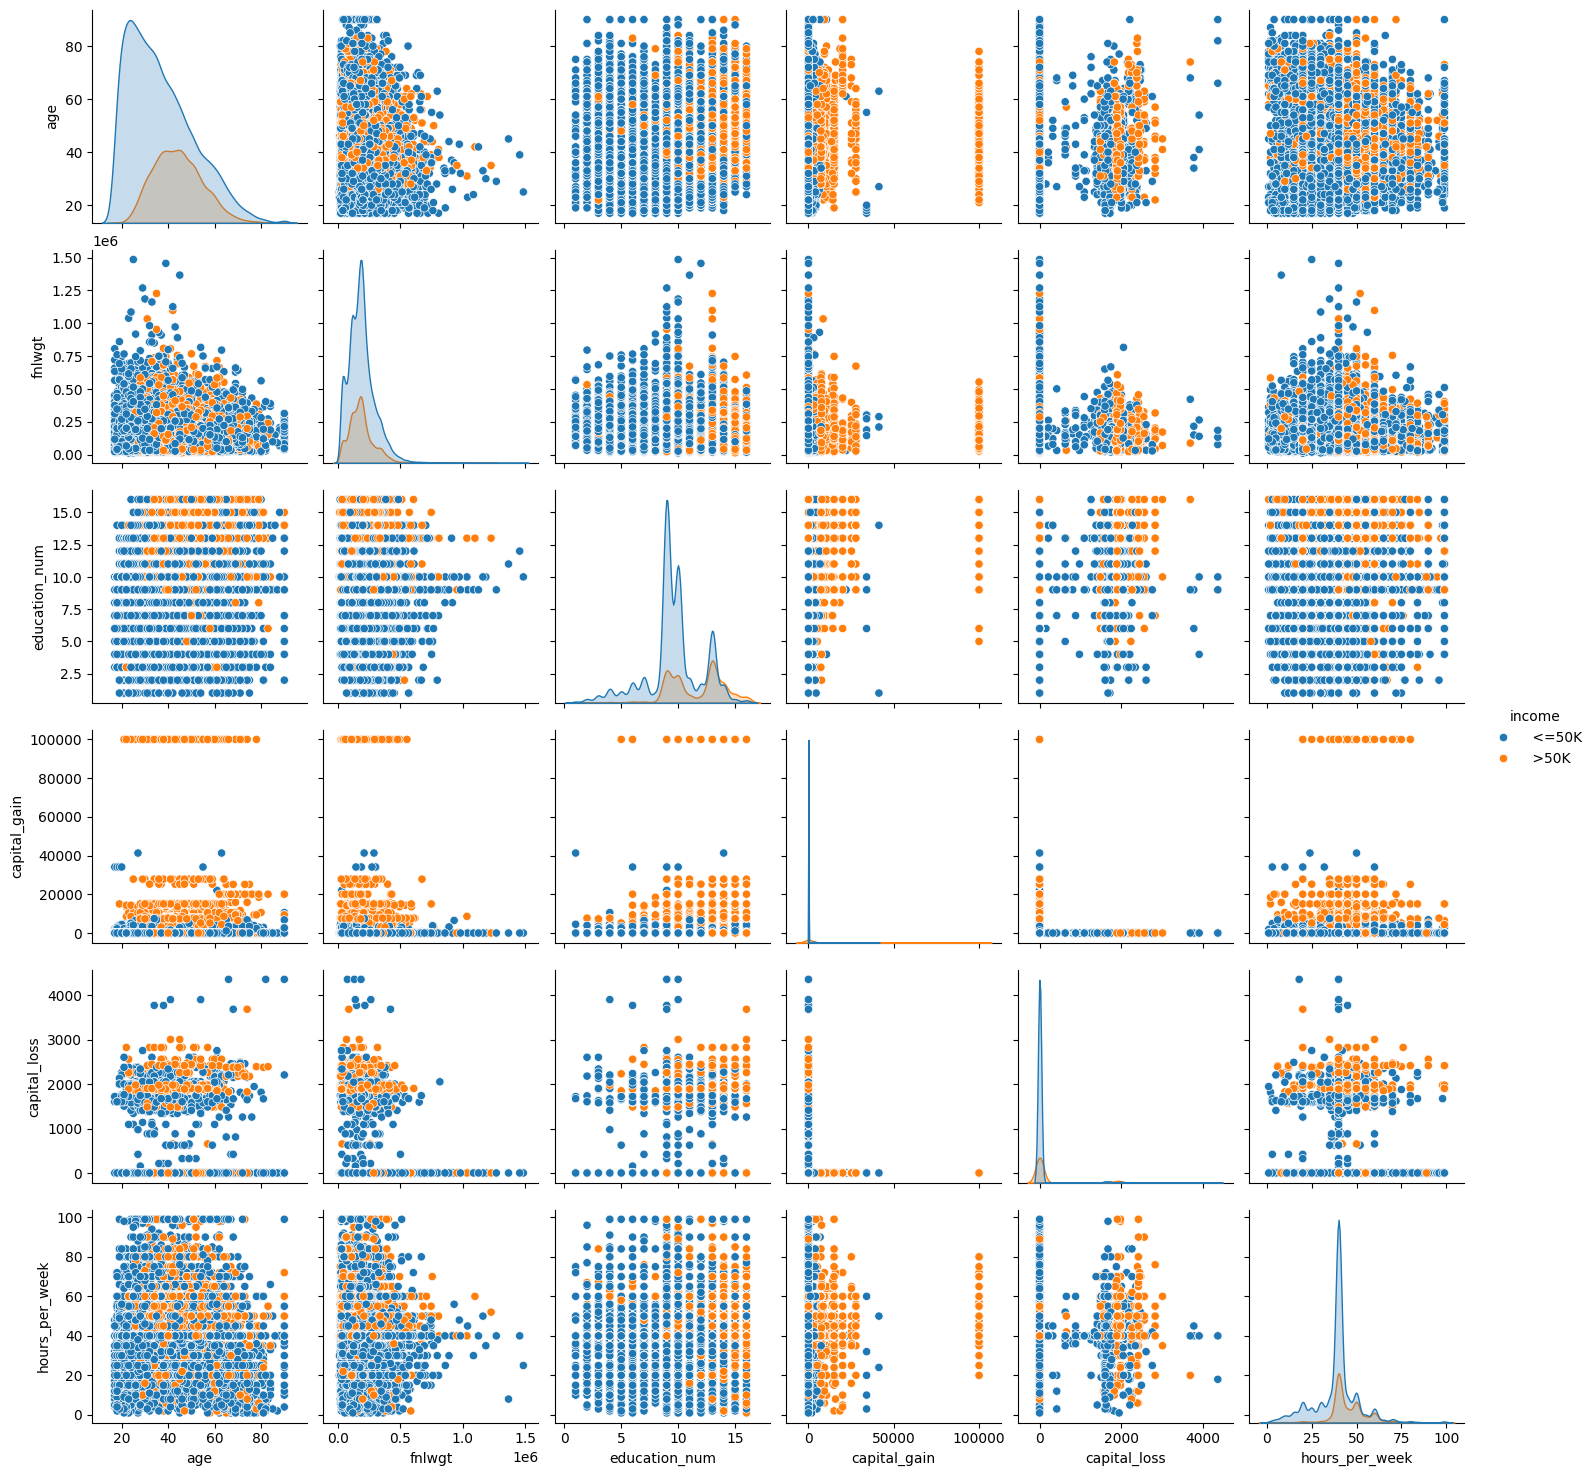

In [26]:
sns.pairplot(hue = "income", data = df)
plt.show()

In [27]:
X = df.drop("income", axis = 1)
y = df["income"]

In [28]:
from sklearn.model_selection import train_test_split

In [29]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3)

In [30]:
categorical_cols = [col for col in X_train.columns if X_train[col].dtype == "str"]

In [31]:
X_train[categorical_cols].isna().sum()

Series([], dtype: float64)

In [32]:
for i in (X_train, X_test):
    i["workclass"] = i["workclass"].fillna(X_train["workclass"].mode()[0])
    i["occupation"] = i["occupation"].fillna(X_train["occupation"].mode()[0])
    i["native_country"] = i["native_country"].fillna(X_train["native_country"].mode()[0])

In [33]:
X_train[categorical_cols].isna().sum()

Series([], dtype: float64)

In [34]:
X_test[categorical_cols].isna().sum()

Series([], dtype: float64)

In [35]:
print(X_train[categorical_cols].nunique())

Series([], dtype: float64)


In [36]:
y_train = y_train.apply(lambda x: 1 if x.strip() == ">50K" else 0)
y_test = y_test.apply(lambda x: 1 if x.strip() == ">50K" else 0)

In [37]:
y_train

6282     0
30573    0
27315    0
21572    0
6003     0
        ..
20320    0
864      0
4238     1
7280     0
572      0
Name: income, Length: 22792, dtype: int64

In [38]:
target_means = y_train.groupby(X_train["native_country"]).mean()

In [39]:
target_means

native_country
Cambodia                      0.266667
Canada                        0.360465
China                         0.263158
Columbia                      0.024390
Cuba                          0.283582
Dominican-Republic            0.035714
Ecuador                       0.200000
El-Salvador                   0.082192
England                       0.375000
France                        0.380952
Germany                       0.343434
Greece                        0.357143
Guatemala                     0.058824
Haiti                         0.074074
Holand-Netherlands            0.000000
Honduras                      0.000000
Hong                          0.250000
Hungary                       0.250000
India                         0.371429
Iran                          0.400000
Ireland                       0.166667
Italy                         0.320000
Jamaica                       0.105263
Japan                         0.365854
Laos                          0.166667
Mexico    

In [40]:
X_train["native_country"] = X_train["native_country"].map(target_means)
X_train["native_country"] = X_train["native_country"].fillna(y_train.mean())

X_test["native_country"] = X_test["native_country"].map(target_means)
X_test["native_country"] = X_test["native_country"].fillna(y_train.mean())

In [41]:
X_train

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country
6282,39,Private,65027,Some-college,10,Married-civ-spouse,Transport-moving,Husband,White,Male,0,0,43,0.245965
30573,34,Private,112564,HS-grad,9,Married-civ-spouse,Transport-moving,Husband,White,Male,0,0,45,0.245965
27315,27,Private,288229,Bachelors,13,Never-married,Adm-clerical,Own-child,Asian-Pac-Islander,Female,0,0,50,0.166667
21572,33,Private,41610,Bachelors,13,Married-civ-spouse,Prof-specialty,Husband,White,Male,0,0,40,0.245965
6003,30,Private,154843,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,0.245965
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20320,45,Private,248993,HS-grad,9,Married-spouse-absent,Farming-fishing,Other-relative,Black,Male,0,0,40,0.245965
864,33,Private,80945,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,0.245965
4238,61,Private,195453,HS-grad,9,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,50,0.245965
7280,27,Federal-gov,246372,HS-grad,9,Married-civ-spouse,Other-service,Husband,White,Male,0,0,40,0.245965


In [42]:
print(categorical_cols)

[]


In [43]:
one_hot_categorical = ['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'sex']

In [44]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

In [45]:
encoder = ColumnTransformer(
    transformers = [("enc", OneHotEncoder(handle_unknown = "ignore", sparse_output=False), one_hot_categorical)],
    remainder = "passthrough"                        
)

In [46]:
X_train = encoder.fit_transform(X_train)
X_test = encoder.transform(X_test)

In [47]:
X_train

array([[ 0.        ,  0.        ,  0.        , ...,  0.        ,
        43.        ,  0.24596542],
       [ 0.        ,  0.        ,  0.        , ...,  0.        ,
        45.        ,  0.24596542],
       [ 0.        ,  0.        ,  0.        , ...,  0.        ,
        50.        ,  0.16666667],
       ...,
       [ 0.        ,  0.        ,  0.        , ...,  0.        ,
        50.        ,  0.24596542],
       [ 1.        ,  0.        ,  0.        , ...,  0.        ,
        40.        ,  0.24596542],
       [ 0.        ,  0.        ,  0.        , ...,  0.        ,
        12.        ,  0.24596542]], shape=(22792, 65))

In [48]:
columns = encoder.get_feature_names_out()

In [49]:
columns

array(['enc__workclass_ Federal-gov', 'enc__workclass_ Local-gov',
       'enc__workclass_ Never-worked', 'enc__workclass_ Private',
       'enc__workclass_ Self-emp-inc', 'enc__workclass_ Self-emp-not-inc',
       'enc__workclass_ State-gov', 'enc__workclass_ Without-pay',
       'enc__education_ 10th', 'enc__education_ 11th',
       'enc__education_ 12th', 'enc__education_ 1st-4th',
       'enc__education_ 5th-6th', 'enc__education_ 7th-8th',
       'enc__education_ 9th', 'enc__education_ Assoc-acdm',
       'enc__education_ Assoc-voc', 'enc__education_ Bachelors',
       'enc__education_ Doctorate', 'enc__education_ HS-grad',
       'enc__education_ Masters', 'enc__education_ Preschool',
       'enc__education_ Prof-school', 'enc__education_ Some-college',
       'enc__marital_status_ Divorced',
       'enc__marital_status_ Married-AF-spouse',
       'enc__marital_status_ Married-civ-spouse',
       'enc__marital_status_ Married-spouse-absent',
       'enc__marital_status_ Never-mar

In [50]:
X_train = pd.DataFrame(X_train, columns = columns)
X_test = pd.DataFrame(X_test, columns = columns)

In [51]:
X_train

,enc__workclass_ Federal-gov,enc__workclass_ Local-gov,enc__workclass_ Never-worked,enc__workclass_ Private,enc__workclass_ Self-emp-inc,enc__workclass_ Self-emp-not-inc,enc__workclass_ State-gov,enc__workclass_ Without-pay,enc__education_ 10th,enc__education_ 11th,...,enc__race_ White,enc__sex_ Female,enc__sex_ Male,remainder__age,remainder__fnlwgt,remainder__education_num,remainder__capital_gain,remainder__capital_loss,remainder__hours_per_week,remainder__native_country
0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,1.0,39.0,65027.0,10.0,0.0,0.0,43.0,0.245965
1,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,1.0,34.0,112564.0,9.0,0.0,0.0,45.0,0.245965
2,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,27.0,288229.0,13.0,0.0,0.0,50.0,0.166667
3,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,1.0,33.0,41610.0,13.0,0.0,0.0,40.0,0.245965
4,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,1.0,30.0,154843.0,9.0,0.0,0.0,40.0,0.245965
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22787,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,45.0,248993.0,9.0,0.0,0.0,40.0,0.245965
22788,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,1.0,33.0,80945.0,9.0,0.0,0.0,40.0,0.245965
22789,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,1.0,61.0,195453.0,9.0,0.0,0.0,50.0,0.245965
22790,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,1.0,27.0,246372.0,9.0,0.0,0.0,40.0,0.245965


In [52]:
X_test

,enc__workclass_ Federal-gov,enc__workclass_ Local-gov,enc__workclass_ Never-worked,enc__workclass_ Private,enc__workclass_ Self-emp-inc,enc__workclass_ Self-emp-not-inc,enc__workclass_ State-gov,enc__workclass_ Without-pay,enc__education_ 10th,enc__education_ 11th,...,enc__race_ White,enc__sex_ Female,enc__sex_ Male,remainder__age,remainder__fnlwgt,remainder__education_num,remainder__capital_gain,remainder__capital_loss,remainder__hours_per_week,remainder__native_country
0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,...,1.0,0.0,1.0,18.0,188476.0,7.0,0.0,0.0,20.0,0.245965
1,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,22.0,310380.0,9.0,0.0,0.0,40.0,0.245965
2,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,43.0,96483.0,9.0,0.0,0.0,40.0,0.193548
3,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,1.0,0.0,28.0,109162.0,14.0,0.0,0.0,50.0,0.245965
4,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,62.0,272209.0,9.0,0.0,0.0,99.0,0.245965
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9764,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,28.0,120471.0,9.0,0.0,0.0,40.0,0.245965
9765,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,1.0,0.0,37.0,125550.0,9.0,0.0,0.0,60.0,0.245965
9766,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,1.0,41.0,38876.0,11.0,0.0,0.0,60.0,0.245965
9767,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,1.0,49.0,268234.0,4.0,0.0,0.0,40.0,0.245965


In [53]:
from sklearn.preprocessing import RobustScaler

In [54]:
scaler = RobustScaler()

In [55]:
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [56]:
from sklearn.ensemble import RandomForestClassifier

In [57]:
rfc = RandomForestClassifier(n_estimators = 10)
rfc.fit(X_train, y_train)

,n_estimators,10
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [58]:
y_pred = rfc.predict(X_test)

In [59]:
from sklearn.metrics import accuracy_score

In [60]:
print(accuracy_score(y_test, y_pred))

0.8420513870406388


In [61]:
rfc = RandomForestClassifier(n_estimators = 100, criterion = "gini")
rfc.fit(X_train, y_train)
y_pred = rfc.predict(X_test)
print(accuracy_score(y_test, y_pred))

0.8561777049851571


In [62]:
rfc = RandomForestClassifier(n_estimators = 100, criterion = "entropy")
rfc.fit(X_train, y_train)
y_pred = rfc.predict(X_test)
print(accuracy_score(y_test, y_pred))

0.8540280479066434


In [63]:
rfc = RandomForestClassifier(n_estimators = 100, criterion = "log_loss")
rfc.fit(X_train, y_train)
y_pred = rfc.predict(X_test)
print(accuracy_score(y_test, y_pred))

0.8533114955471389


In [64]:
rf_params = {"max_depth": [5, 8, 15, None, 10],
             "max_features": [5, 7, "auto", 8],
             "min_samples_split": [2, 8, 15, 20],
             "n_estimators": [100, 200, 500, 1000]}

In [65]:
from sklearn.model_selection import RandomizedSearchCV

In [66]:
rfc = RandomForestClassifier()
rscv = RandomizedSearchCV(estimator=rfc, param_distributions=rf_params,n_iter=10,cv=3,verbose=1,n_jobs=-1)
rscv.fit(X_train, y_train)

Fitting 3 folds for each of 10 candidates, totalling 30 fits


,estimator,RandomForestClassifier()
,param_distributions,"{'max_depth': [5, 8, ...], 'max_features': [5, 7, ...], 'min_samples_split': [2, 8, ...], 'n_estimators': [100, 200, ...]}"
,n_iter,10
,scoring,None
,n_jobs,-1
,refit,True
,cv,3
,verbose,1
,pre_dispatch,'2*n_jobs'
,random_state,None
,error_score,nan


In [67]:
y_pred = rscv.predict(X_test)
print(f'Model accuracy score with default decision-trees : {accuracy_score(y_test, y_pred)}')

Model accuracy score with default decision-trees : 0.8633432285802027


In [68]:
rscv.best_params_

{'n_estimators': 100,
 'min_samples_split': 15,
 'max_features': 8,
 'max_depth': None}

In [69]:
from sklearn.metrics import confusion_matrix

In [70]:
print(confusion_matrix(y_test, y_pred))

[[6950  465]
 [ 870 1484]]
